# PTB-XL multilabel SVM (100 Hz) — engineered ECG features

Extracts **time-domain, waveform-shape, Hjorth, and frequency-domain features from all 12 ECG leads** and predicts the five diagnostic superclasses. Each recording is represented by 39 features per lead (468 features total). The RBF SVM is tuned on fold 9; fold 10 is reserved for final evaluation.

The features are descriptive signal measurements, not clinical diagnoses or manually detected ECG intervals.

In [34]:
from pathlib import Path
import ast
import urllib.request

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import wfdb
from scipy.stats import kurtosis, skew
from scipy.signal import welch
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    classification_report,
    f1_score,
    multilabel_confusion_matrix,
)
from sklearn.multiclass import OneVsRestClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from pathlib import Path

# Automatically find the project root
for p in [Path.cwd(), *Path.cwd().parents]:
    if (p / "data" / "ptb-xl").is_dir():
        PROJECT = p
        break
else:
    raise FileNotFoundError(
        "Could not find data/ptb-xl. Check your working directory."
    )


DATA = next((PROJECT / "data/ptb-xl").rglob("ptbxl_database.csv")).parent
SCP_FILE = DATA / "scp_statements.csv"

CLASSES = ["NORM", "MI", "STTC", "CD", "HYP"]
N_LEADS = 12
print("Using dataset:", DATA)



Using dataset: c:\Users\radun\Desktop\ecg-classification\data\ptb-xl


## Load labels, extract features, and split the data

For every lead, the extractor computes:
- **16 original statistical features** (mean, standard deviation, extrema, range, RMS, percentiles, skewness, kurtosis, and first-difference statistics).
- **23 additional features** covering robust amplitude spread, waveform variation, zero crossings, slope changes, Hjorth descriptors, and Welch power-spectrum characteristics.

That gives **39 features per lead × 12 leads = 468 features per ECG**. PTB-XL patient-level folds remain separate: folds 1–8 for training, fold 9 for validation, and fold 10 for testing.

## Tune the SVM on the validation fold
Compare a grid of `C` and `gamma` values using the engineered 468-feature representation. The configuration with the highest validation macro F1 is retained. The test fold is not used for model selection.

In [35]:
df = pd.read_csv(DATA / "ptbxl_database.csv")
df["scp_codes"] = df["scp_codes"].apply(ast.literal_eval)
scp = pd.read_csv(SCP_FILE, index_col=0)
scp = scp[scp["diagnostic"] == 1]


def make_labels(codes):
    """Map the ECG's diagnostic SCP codes to the five superclass labels."""
    found = {
        scp.at[code, "diagnostic_class"]
        for code in codes
        if code in scp.index and pd.notna(scp.at[code, "diagnostic_class"])
    }
    return [int(label in found) for label in CLASSES]


Y = np.asarray(df["scp_codes"].apply(make_labels).tolist(), dtype=np.uint8)


def extract_lead_features(signal, sampling_rate=100):
    """
    Extract 39 descriptive features from one 10-second ECG lead.

    The original 16 features are retained, and 23 complementary features
    are added. PTB-XL's low-resolution records are sampled at 100 Hz.
    """
    x = np.asarray(signal, dtype=np.float64)
    x = np.nan_to_num(x, nan=0.0, posinf=0.0, neginf=0.0)
    dx = np.diff(x)
    ddx = np.diff(dx)

    # Basic amplitudes and distribution (original features 1–6).
    mean = np.mean(x)                         # 1. Mean amplitude: baseline level.
    std = np.std(x)                           # 2. Standard deviation: overall amplitude variability.
    minimum = np.min(x)                       # 3. Minimum sample: most negative excursion.
    maximum = np.max(x)                       # 4. Maximum sample: most positive excursion.
    peak_to_peak = np.ptp(x)                  # 5. Peak-to-peak range: total amplitude span.
    rms = np.sqrt(np.mean(x ** 2))            # 6. RMS amplitude: signal magnitude/energy scale.

    # Distribution percentiles (original features 7–11).
    p10, p25, p50, p75, p90 = np.percentile(x, [10, 25, 50, 75, 90])
                                                # 7–11. Robust amplitude landmarks, less sensitive to extremes.

    # Distribution shape (original features 12–13).
    signal_skew = skew(x, bias=False)          # 12. Skewness: asymmetry of the amplitude distribution.
    signal_kurtosis = kurtosis(x, bias=False) # 13. Excess kurtosis: heaviness of distribution tails.

    # First-difference / local-change statistics (original features 14–16).
    mean_abs_diff = np.mean(np.abs(dx)) if dx.size else 0.0
                                                # 14. Mean absolute first difference: average sample-to-sample change.
    std_diff = np.std(dx) if dx.size else 0.0 # 15. Variability of sample-to-sample changes.
    max_abs_diff = np.max(np.abs(dx)) if dx.size else 0.0
                                                # 16. Largest absolute first difference: strongest local change.

    # Additional robust amplitude and spread features (17–21).
    median_abs_deviation = np.median(np.abs(x - p50))
                                                # 17. Median absolute deviation: robust spread around the median.
    interquartile_range = p75 - p25             # 18. IQR: spread of the central 50% of amplitudes.
    p05, p95 = np.percentile(x, [5, 95])        # 19–20. 5th/95th percentiles: robust lower/upper amplitude levels.
    mean_abs_amplitude = np.mean(np.abs(x))     # 21. Mean absolute amplitude: average magnitude without sign cancellation.

    # Waveform-shape / variation features (22–27).
    waveform_length = np.sum(np.abs(dx)) / max(len(x) - 1, 1)
                                                # 22. Average waveform length: cumulative absolute change per interval.
    centered = x - mean
    zero_crossing_rate = np.mean(centered[:-1] * centered[1:] < 0) if len(x) > 1 else 0.0
                                                # 23. Fraction of adjacent samples crossing the mean level.
    slope_sign_change_rate = (
        np.mean(dx[:-1] * dx[1:] < 0) if len(dx) > 1 else 0.0
    )                                           # 24. Fraction of adjacent slopes changing sign; rough turning-point density.
    first_diff_rms = np.sqrt(np.mean(dx ** 2)) if dx.size else 0.0
                                                # 25. RMS of first difference: strength of rapid sample-to-sample changes.
    second_diff_rms = np.sqrt(np.mean(ddx ** 2)) if ddx.size else 0.0
                                                # 26. RMS of second difference: strength of changes in slope/curvature.
    crest_factor = np.max(np.abs(x)) / (rms + 1e-12)
                                                # 27. Peak magnitude divided by RMS: prominence of large peaks.
    shape_factor = rms / (mean_abs_amplitude + 1e-12)
                                                # 28. RMS divided by mean absolute amplitude: amplitude-shape descriptor.

    # Hjorth time-domain descriptors (29–31).
    activity = np.var(x)                       # 29. Hjorth activity: signal variance (power-like measure).
    mobility = np.sqrt(np.var(dx) / (activity + 1e-12)) if dx.size else 0.0
                                                # 30. Hjorth mobility: characteristic rate of signal variation.
    derivative_mobility = (
        np.sqrt(np.var(ddx) / (np.var(dx) + 1e-12)) if ddx.size else 0.0
    )
    hjorth_complexity = derivative_mobility / (mobility + 1e-12)
                                                # 31. Hjorth complexity: how the rate of variation itself changes.

    # Welch power spectral density (32–39).
    # At 100 Hz, Nyquist frequency is 50 Hz. These broad bands summarize
    # low-, mid-, and higher-frequency signal power without detecting beats.
    frequencies, psd = welch(
        x, fs=sampling_rate, nperseg=min(256, len(x)),
        detrend="constant", scaling="density"
    )
    band_mask = (frequencies >= 0.5) & (frequencies <= 40.0)
    band_freqs = frequencies[band_mask]
    band_psd = psd[band_mask]
    total_power = np.trapz(band_psd, band_freqs) if band_psd.size > 1 else 0.0
                                                # 32. Total 0.5–40 Hz power: overall in-band spectral energy.

    def relative_band_power(low, high):
        mask = (frequencies >= low) & (frequencies < high)
        power = np.trapz(psd[mask], frequencies[mask]) if np.count_nonzero(mask) > 1 else 0.0
        return power / (total_power + 1e-12)

    rel_power_0p5_5 = relative_band_power(0.5, 5.0)
                                                # 33. Relative 0.5–5 Hz power: share in slower baseline/morphology changes.
    rel_power_5_15 = relative_band_power(5.0, 15.0)
                                                # 34. Relative 5–15 Hz power: share in mid-frequency ECG content.
    rel_power_15_40 = relative_band_power(15.0, 40.0)
                                                # 35. Relative 15–40 Hz power: share in faster waveform detail/noise.
    if band_psd.size and np.sum(band_psd) > 0:
        spectral_centroid = np.sum(band_freqs * band_psd) / np.sum(band_psd)
                                                # 36. Spectral centroid: power-weighted average frequency.
        dominant_frequency = band_freqs[np.argmax(band_psd)]
                                                # 37. Dominant frequency: frequency with greatest in-band PSD.
        normalized_psd = band_psd / np.sum(band_psd)
        spectral_entropy = -np.sum(
            normalized_psd * np.log(normalized_psd + 1e-12)
        ) / np.log(len(normalized_psd) + 1e-12)
                                                # 38. Normalized spectral entropy: how spread out spectral power is.
        cumulative_power = np.cumsum(band_psd)
        spectral_rolloff_95 = band_freqs[
            min(np.searchsorted(cumulative_power, 0.95 * cumulative_power[-1]), len(band_freqs) - 1)
        ]                                           # 39. 95% spectral rolloff: frequency below which 95% of in-band PSD lies.
    else:
        spectral_centroid = dominant_frequency = spectral_entropy = spectral_rolloff_95 = 0.0

    return np.asarray([
        mean, std, minimum, maximum, peak_to_peak, rms,
        p10, p25, p50, p75, p90, signal_skew, signal_kurtosis,
        mean_abs_diff, std_diff, max_abs_diff,
        median_abs_deviation, interquartile_range, p05, p95,
        mean_abs_amplitude, waveform_length, zero_crossing_rate,
        slope_sign_change_rate, first_diff_rms, second_diff_rms,
        crest_factor, shape_factor, activity, mobility,
        hjorth_complexity, total_power, rel_power_0p5_5,
        rel_power_5_15, rel_power_15_40, spectral_centroid,
        dominant_frequency, spectral_entropy, spectral_rolloff_95,
    ], dtype=np.float32)


# Feature names are repeated for each lead so that every column is traceable.
FEATURE_NAMES_PER_LEAD = [
    "mean", "std", "min", "max", "peak_to_peak", "rms",
    "p10", "p25", "p50", "p75", "p90", "skewness", "kurtosis",
    "mean_abs_first_diff", "std_first_diff", "max_abs_first_diff",
    "median_abs_deviation", "interquartile_range", "p05", "p95",
    "mean_abs_amplitude", "waveform_length_per_interval",
    "zero_crossing_rate", "slope_sign_change_rate",
    "first_diff_rms", "second_diff_rms", "crest_factor", "shape_factor",
    "hjorth_activity", "hjorth_mobility", "hjorth_complexity",
    "total_power_0p5_40Hz", "relative_power_0p5_5Hz",
    "relative_power_5_15Hz", "relative_power_15_40Hz",
    "spectral_centroid", "dominant_frequency", "spectral_entropy",
    "spectral_rolloff_95",
]
LEAD_NAMES = [
    "I", "II", "III", "aVR", "aVL", "aVF",
    "V1", "V2", "V3", "V4", "V5", "V6"
]
FEATURE_NAMES = [
    f"{lead}_{feature}"
    for lead in LEAD_NAMES
    for feature in FEATURE_NAMES_PER_LEAD
]

# Load each record and compute features independently for all 12 leads.
# PTB-XL 100 Hz records are normally 1,000 samples × 12 leads (10 seconds).
try:
    from tqdm.auto import tqdm
    records = tqdm(df["filename_lr"], desc="Extracting ECG features")
except ImportError:
    records = df["filename_lr"]

feature_rows = []
expected_shape = None

for filename in records:
    signal, _ = wfdb.rdsamp(str(DATA / filename))
    signal = np.asarray(signal, dtype=np.float32)

    if signal.ndim != 2 or signal.shape[1] != N_LEADS:
        raise ValueError(
            f"Expected a 2D ECG with {N_LEADS} leads, "
            f"but {filename} has shape {signal.shape}"
        )

    if expected_shape is None:
        expected_shape = signal.shape
    elif signal.shape != expected_shape:
        raise ValueError(
            f"Inconsistent ECG shape: {filename} has {signal.shape}; "
            f"expected {expected_shape}"
        )

    # Concatenate 39 features from each of the 12 leads.
    feature_rows.append(np.concatenate([
        extract_lead_features(signal[:, lead], sampling_rate=100)
        for lead in range(N_LEADS)
    ]))

X = np.stack(feature_rows).astype(np.float32, copy=False)
X = np.nan_to_num(X, nan=0.0, posinf=0.0, neginf=0.0)

if X.shape[1] != len(FEATURE_NAMES):
    raise RuntimeError(
        f"Feature count mismatch: matrix has {X.shape[1]} columns, "
        f"but {len(FEATURE_NAMES)} feature names were defined."
    )

fold = df["strat_fold"].to_numpy()
train_mask, val_mask, test_mask = fold <= 8, fold == 9, fold == 10

X_train, X_val, X_test = X[train_mask], X[val_mask], X[test_mask]
Y_train, Y_val, Y_test = Y[train_mask], Y[val_mask], Y[test_mask]

print("Original ECG shape (samples, leads):", expected_shape)
print("Feature matrix:", X.shape)
print("Features per lead:", len(FEATURE_NAMES_PER_LEAD))
print("Total features per ECG:", X.shape[1])
print("Train / validation / test:", X_train.shape, X_val.shape, X_test.shape)
print("Training positives:", dict(zip(CLASSES, Y_train.sum(axis=0))))


C:\Users\radun\AppData\Roaming\Python\Python313\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Extracting ECG features:   0%|          | 0/21799 [00:00<?, ?it/s]C:\Users\radun\AppData\Local\Temp\ipykernel_29944\1693198877.py:100: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  total_power = np.trapz(band_psd, band_freqs) if band_psd.size > 1 else 0.0
C:\Users\radun\AppData\Local\Temp\ipykernel_29944\1693198877.py:105: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  power = np.trapz(psd[mask], frequencies[mask]) if np.count_nonzero(mask) > 1 else 0.0
Extracting ECG features: 100%|██████████| 21799/21799 [06:37<00:00, 54.85it/s]


Original ECG shape (samples, leads): (1000, 12)
Feature matrix: (21799, 468)
Features per lead: 39
Total features per ECG: 468
Train / validation / test: (17418, 468) (2183, 468) (2198, 468)
Training positives: {'NORM': np.uint64(7596), 'MI': np.uint64(4379), 'STTC': np.uint64(4186), 'CD': np.uint64(3907), 'HYP': np.uint64(2119)}


In [36]:
import time

C_VALUES = [1,5,10]
GAMMA_VALUES = ["scale", 0.00002, 0.00005, 0.0001, 0.0002]
THRESHOLDS = [-0.5, -0.25, 0, 0.1, 0.25, 0.5, 0.75]

best_score = -np.inf
best_model = None
best_params = None
best_threshold = None

total_start = time.perf_counter()

for C in C_VALUES:
    for gamma in GAMMA_VALUES:
        run_start = time.perf_counter()

        candidate = make_pipeline(
            StandardScaler(),
            OneVsRestClassifier(
                SVC(
                    kernel="rbf",
                    C=C,
                    gamma=gamma,
                    class_weight="balanced",
                ),
                n_jobs=-1,
            ),
        )

        candidate.fit(X_train, Y_train)
        val_scores = candidate.decision_function(X_val)

        config_best_score = -np.inf
        config_best_threshold = None

        for threshold in THRESHOLDS:
            val_predictions = (val_scores >= threshold).astype(np.uint8)
            val_macro_f1 = f1_score(
                Y_val, val_predictions, average="macro", zero_division=0
            )

            if val_macro_f1 > config_best_score:
                config_best_score = val_macro_f1
                config_best_threshold = threshold

            if val_macro_f1 > best_score:
                best_score = val_macro_f1
                best_model = candidate
                best_params = {"C": C, "gamma": gamma}
                best_threshold = threshold

        run_time = time.perf_counter() - run_start
        print(
            f"C={C}, gamma={gamma}: "
            f"best validation macro F1={config_best_score:.4f} "
            f"(threshold={config_best_threshold}) | "
            f"time={run_time:.2f}s"
        )

total_time = time.perf_counter() - total_start

print("\nBest parameters:", best_params)
print("Best threshold:", best_threshold)
print(f"Best validation macro F1: {best_score:.4f}")
print(f"Total execution time: {total_time:.2f}s")


C=1, gamma=scale: best validation macro F1=0.6950 (threshold=0.1) | time=77.31s
C=1, gamma=2e-05: best validation macro F1=0.6456 (threshold=0.1) | time=93.17s
C=1, gamma=5e-05: best validation macro F1=0.6573 (threshold=0.25) | time=86.54s
C=1, gamma=0.0001: best validation macro F1=0.6648 (threshold=0.25) | time=79.62s
C=1, gamma=0.0002: best validation macro F1=0.6744 (threshold=0.25) | time=75.61s
C=5, gamma=scale: best validation macro F1=0.6897 (threshold=0) | time=112.37s
C=5, gamma=2e-05: best validation macro F1=0.6634 (threshold=0.25) | time=79.42s
C=5, gamma=5e-05: best validation macro F1=0.6718 (threshold=0.25) | time=74.18s
C=5, gamma=0.0001: best validation macro F1=0.6784 (threshold=0.25) | time=70.90s
C=5, gamma=0.0002: best validation macro F1=0.6897 (threshold=0.25) | time=69.06s
C=10, gamma=scale: best validation macro F1=0.6763 (threshold=0) | time=145.59s
C=10, gamma=2e-05: best validation macro F1=0.6676 (threshold=0.25) | time=74.99s
C=10, gamma=5e-05: best vali

## Final test evaluation
Evaluate the selected model once on fold 10. Because this is multilabel classification, the notebook displays a separate 2×2 confusion matrix for each superclass.


Selected parameters: {'C': 1, 'gamma': 'scale'}
Selected threshold: 0.1
Test macro F1: 0.6747
              precision    recall  f1-score   support

        NORM       0.76      0.87      0.81       963
          MI       0.62      0.64      0.63       550
        STTC       0.62      0.78      0.69       521
          CD       0.67      0.67      0.67       496
         HYP       0.51      0.66      0.57       262

   micro avg       0.66      0.75      0.71      2792
   macro avg       0.64      0.72      0.67      2792
weighted avg       0.67      0.75      0.71      2792
 samples avg       0.67      0.75      0.69      2792



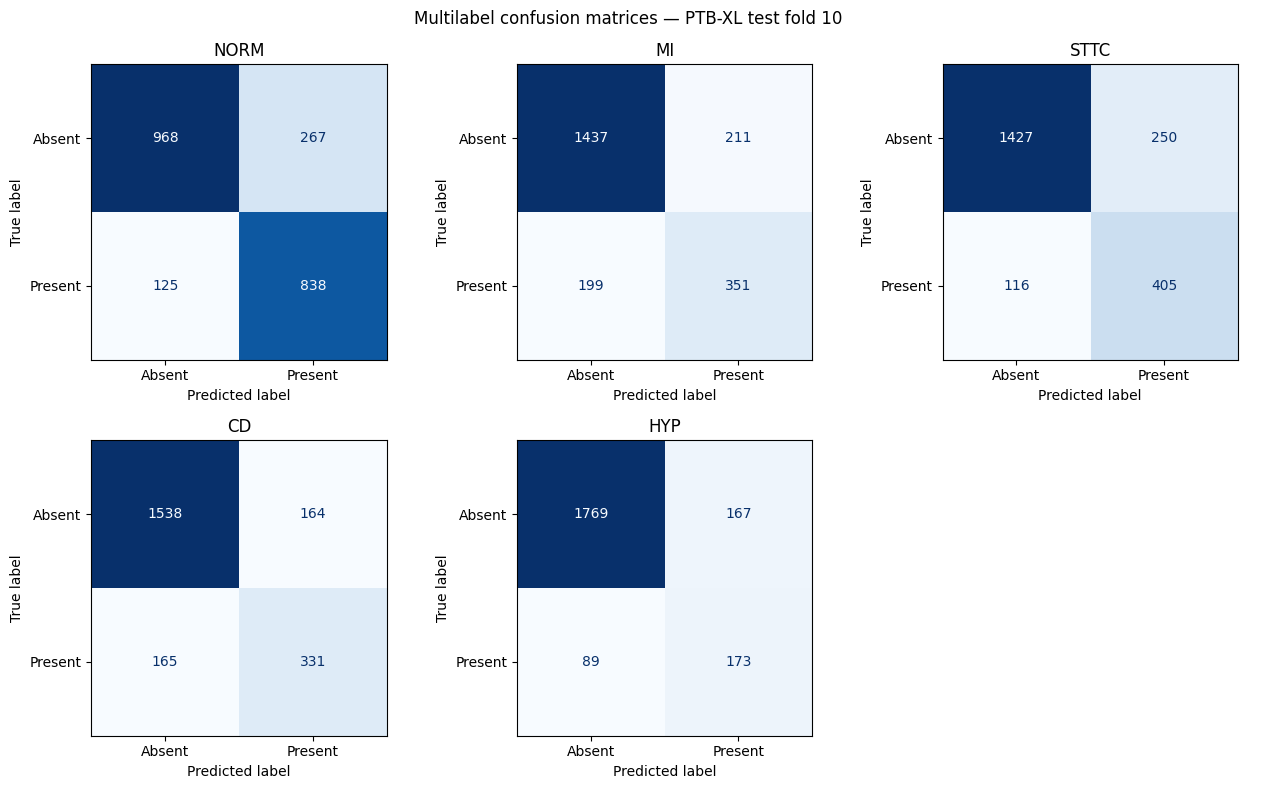

In [37]:
# Use the threshold selected on validation data (rather than SVC's default 0).
test_scores = best_model.decision_function(X_test)
test_predictions = (test_scores >= best_threshold).astype(np.uint8)

print("Selected parameters:", best_params)
print("Selected threshold:", best_threshold)
print("Test macro F1:", round(
    f1_score(Y_test, test_predictions, average="macro", zero_division=0), 4
))
print(classification_report(
    Y_test, test_predictions, target_names=CLASSES, zero_division=0
))

confusion_matrices = multilabel_confusion_matrix(Y_test, test_predictions)
fig, axes = plt.subplots(2, 3, figsize=(13, 8))
for ax, class_name, matrix in zip(axes.flat, CLASSES, confusion_matrices):
    ConfusionMatrixDisplay(
        confusion_matrix=matrix,
        display_labels=["Absent", "Present"],
    ).plot(ax=ax, cmap="Blues", colorbar=False, values_format="d")
    ax.set_title(class_name)

axes.flat[-1].axis("off")
fig.suptitle("Multilabel confusion matrices — PTB-XL test fold 10")
plt.tight_layout()
plt.show()
